# ISE-A5: counterexample study of YODA's fault-tolerance claims

This notebook reads **only raw result files** from `results/baseline/` and `results/after/`, plus the
frozen configs. Every number below is recomputed from those files; no result is typed in by hand.
The claims, oracles and thresholds are defined in `docs/protocol_v1.md`, which was frozen at tag
`a5-protocol-frozen`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore', category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from a5 import analysis as A
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
base = A.load('configs/baseline.yaml')
after = A.load('configs/after.yaml') if (ROOT / 'results/after/metrics.csv').exists() else None
print('protocol hash file:'); print((ROOT / 'results/protocol_hash.txt').read_text())

protocol hash file:
3a83c7a34b559691fd365d563e124b9c0c277c071d5436f2c2a97d97d2a4e050  docs/protocol_v1.md
c7197c82ec5ee7de89c96599405541bf543114998753389faafd2fcb0ddae0b6  configs/baseline.yaml



## 1. Reproduction: training runs and agreement with the published catalogue

In [2]:
tr = pd.DataFrame([{k: v for k, v in t.items() if k != 'history'} for t in base['training']])
display(tr)
print('labelled in SoSt:', base['meta']['n_labelled_in_sost'], base['meta']['labelled_by_otype'])
display(base['agreement'])
display(base['agreement'].drop(columns='seed').mean().to_frame('mean over seeds').T)
print('NOTE: Jaccard on E_rand is trivially 0 (E_rand excludes all published candidates; see results/baseline/rerun_log.md).')
print('Corrected agreement on the full SoSt minus training sources:')
af = pd.read_csv(ROOT / 'results/baseline/agreement_full.csv'); display(af)
display(af.drop(columns='seed').mean().to_frame('mean over seeds').T)

,seed,epochs_run,n_components,n_train,n_test,n_train_by_label,n_test_by_label,best_val_precision,train_seconds
0,11,121,12,42491,4722,"{'0': 42323, '1': 111, '2': 57}","{'0': 4703, '1': 14, '2': 5}",0.600000,167.3
1,22,91,12,42491,4722,"{'0': 42323, '1': 111, '2': 57}","{'0': 4703, '1': 15, '2': 4}",0.195122,131.7
2,33,158,12,42491,4722,"{'0': 42328, '1': 102, '2': 61}","{'0': 4698, '1': 15, '2': 9}",0.194444,250.6


labelled in SoSt: 187 {'TT*': 102, 'Be*': 67, 'Ae*': 18}


,seed,jaccard_PMS,spearman_PMS,n_repro_PMS,n_published_PMS,jaccard_CBe,spearman_CBe,n_repro_CBe,n_published_CBe,cand_published_PMS_recovered,cand_published_CBe_recovered
0,11,0.0,0.532476,156,0,0.0,0.385805,193,0,0.415797,0.945508
1,22,0.0,0.609115,655,0,0.0,0.325983,98,0,0.701578,0.941176
2,33,0.0,0.581485,775,0,0.0,0.457272,263,0,0.810869,0.966325


,jaccard_PMS,spearman_PMS,n_repro_PMS,n_published_PMS,jaccard_CBe,spearman_CBe,n_repro_CBe,n_published_CBe,cand_published_PMS_recovered,cand_published_CBe_recovered
mean over seeds,0.0,0.574359,528.666667,0.0,0.0,0.389687,184.666667,0.0,0.642748,0.951003


NOTE: Jaccard on E_rand is trivially 0 (E_rand excludes all published candidates; see results/baseline/rerun_log.md).
Corrected agreement on the full SoSt minus training sources:


,seed,n_eval,n_repro_PMS,n_published_PMS,jaccard_PMS,published_recovered_PMS,spearman_PMS,n_repro_CBe,n_published_CBe,jaccard_CBe,published_recovered_CBe,spearman_CBe
0,11,4108558,9554,8432,0.242127,0.415797,0.537629,10364,679,0.061725,0.945508,0.390550
1,22,4108551,33197,8431,0.165626,0.701578,0.612524,6086,680,0.104473,0.941176,0.329036
2,33,4108542,37771,8428,0.173606,0.810869,0.579227,12634,683,0.052145,0.966325,0.453758


,n_eval,n_repro_PMS,n_published_PMS,jaccard_PMS,published_recovered_PMS,spearman_PMS,n_repro_CBe,n_published_CBe,jaccard_CBe,published_recovered_CBe,spearman_CBe
mean over seeds,4.108550e+06,26840.666667,8430.333333,0.193786,0.642748,0.57646,9694.666667,680.666667,0.072781,0.951003,0.391115


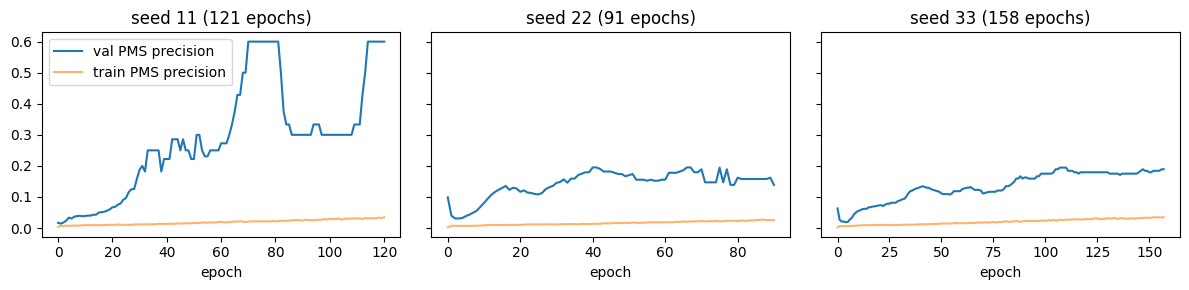

In [3]:
fig, ax = plt.subplots(1, len(base['training']), figsize=(4 * len(base['training']), 3), sharey=True)
for a, t in zip(np.atleast_1d(ax), base['training']):
    a.plot(t['history']['val_precision'], label='val PMS precision')
    a.plot(t['history']['precision'], label='train PMS precision', alpha=.6)
    a.set_title(f"seed {t['seed']} ({t['epochs_run']} epochs)"); a.set_xlabel('epoch')
np.atleast_1d(ax)[0].legend(); plt.tight_layout(); plt.show()

## 2. Baseline: per-cell results (all grid cells)

In [4]:
tb = A.cell_table(base)
cols = ['cell','flip_PMS_cand','flip_PMS_cand_lo','flip_PMS_cand_hi','flip_CBe_cand','flip_CBe_cand_lo',
        'flip_CBe_cand_hi','flip_PMS_test','flip_CBe_test','recall_PMS','d_recall_PMS','d_recall_lo','d_recall_hi',
        'precision_PMS','d_precision_PMS','dN_PMS_rand','dN_CBe_rand','dN_PMS_cand','dN_CBe_cand']
display(tb[cols].round(4))

,cell,flip_PMS_cand,flip_PMS_cand_lo,flip_PMS_cand_hi,flip_CBe_cand,flip_CBe_cand_lo,flip_CBe_cand_hi,flip_PMS_test,flip_CBe_test,recall_PMS,d_recall_PMS,d_recall_lo,d_recall_hi,precision_PMS,d_precision_PMS,dN_PMS_rand,dN_CBe_rand,dN_PMS_cand,dN_CBe_cand
0,c00_clean_0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.00,0.0000,0.7492,0.0000,0.0000,0.0000,0.3786,0.0000,0.0000,0.0000,0.0000,0.0000
1,c01_F1_resample_0.1,0.0240,0.0216,0.0263,0.0235,0.0197,0.0272,0.03,0.0465,0.7492,0.0000,0.0000,0.0000,0.3809,0.0023,8.6667,-4.3333,-110.0000,2.0000
2,c02_F1_resample_0.28,0.0655,0.0619,0.0693,0.0597,0.0540,0.0654,0.05,0.1628,0.6778,-0.0714,-0.1429,0.0000,0.3472,-0.0314,20.0000,-10.0000,-294.0000,25.3333
3,c03_F1_resample_0.44,0.1050,0.1003,0.1097,0.0953,0.0884,0.1024,0.08,0.1163,0.6603,-0.0889,-0.1778,-0.0222,0.3383,-0.0403,13.3333,-16.0000,-474.0000,36.0000
4,c04_F1_resample_0.72,0.1748,0.1692,0.1804,0.1507,0.1416,0.1593,0.17,0.1860,0.6127,-0.1365,-0.2524,-0.0222,0.3456,-0.0330,40.3333,-22.6667,-780.6667,73.3333
5,c05_F1_noise_0.1,0.0080,0.0067,0.0094,0.0114,0.0089,0.0140,0.02,0.0233,0.7270,-0.0222,-0.0667,0.0000,0.3756,-0.0030,0.0000,2.6667,-28.0000,-6.0000
6,c06_F1_noise_0.28,0.0215,0.0193,0.0238,0.0289,0.0249,0.0331,0.07,0.0465,0.7476,-0.0016,-0.0714,0.0651,0.3886,0.0100,-8.0000,6.3333,-79.3333,-6.0000
7,c07_F1_noise_0.44,0.0302,0.0277,0.0328,0.0466,0.0417,0.0518,0.05,0.0465,0.7270,-0.0222,-0.0667,0.0000,0.3716,-0.0070,-18.3333,12.6667,-107.0000,-7.6667
8,c08_F1_noise_0.72,0.0485,0.0454,0.0517,0.0750,0.0687,0.0812,0.10,0.2558,0.6794,-0.0698,-0.1588,0.0000,0.3825,0.0039,-23.3333,24.3333,-156.0000,-21.6667
9,c09_F2_allwise_swap_0.01,0.0081,0.0068,0.0096,0.0086,0.0065,0.0108,0.00,0.0233,0.7492,0.0000,0.0000,0.0000,0.3743,-0.0043,1.0000,16.0000,-42.6667,-16.0000


## 3. Decision on C1 (paper-realistic cells, frozen thresholds)

In [5]:
db = A.decisions(base, tb)
display(db)
C1_falsified = bool(db.falsifies_C1.any())
print('C1 FALSIFIED' if C1_falsified else 'C1 SURVIVED', '(baseline)')

,cell,flip_PMS_cand,CI_lo_PMS,flip_CBe_cand,CI_lo_CBe,d_recall_PMS,d_recall_CI,rule_a_PMS,rule_a_CBe,rule_b_recall,falsifies_C1
0,c03_F1_resample_0.44,0.105002,0.100341,0.095341,0.088421,-0.088889,"[-0.1778, -0.0222]",True,True,True,True
1,c07_F1_noise_0.44,0.030203,0.027666,0.046594,0.041673,-0.022222,"[-0.0667, 0.0000]",False,False,False,False
2,c10_F2_allwise_swap_0.023,0.018995,0.017047,0.018761,0.015685,-0.023810,"[-0.0714, 0.0000]",False,False,False,False
3,c12_F3_iphas_swap_0.013,0.003539,0.002655,0.002460,0.001384,0.000000,"[0.0000, 0.0000]",False,False,False,False


C1 FALSIFIED (baseline)


## 4. Flip rate vs fault rate (95% bootstrap CI), PMS and CBe, on published candidates

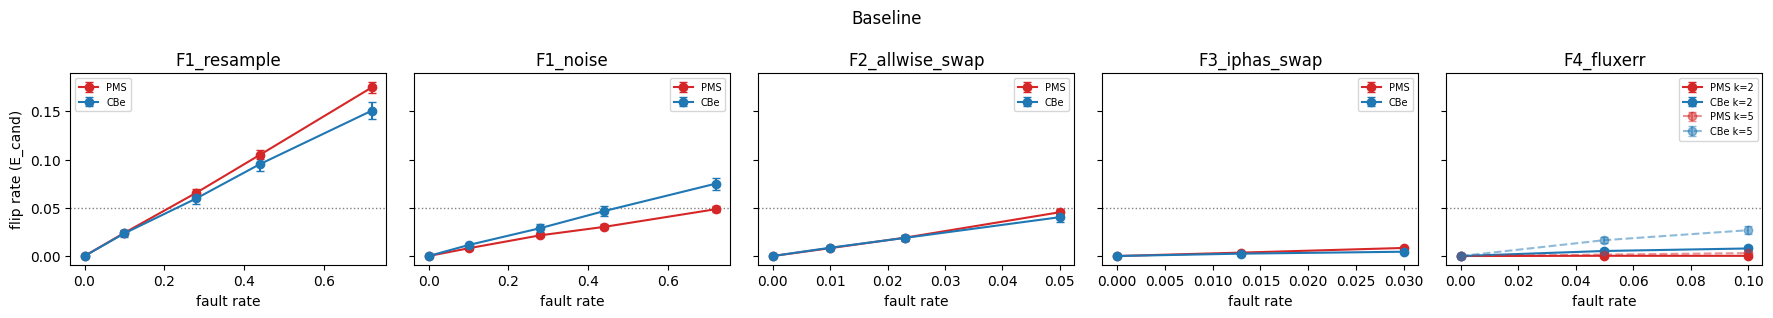

In [6]:
def curves(tab, title):
    faults = [f for f in tab.fault.unique() if f != 'clean']
    fig, axes = plt.subplots(1, len(faults), figsize=(3.6 * len(faults), 3.2), sharey=True)
    for ax, f in zip(axes, faults):
        for k_val, sub in tab[tab.fault == f].groupby(tab.k.fillna(0)):
            sub = pd.concat([tab[tab.fault == 'clean'], sub]).sort_values('rate')
            for c, col in [('PMS', 'C3'), ('CBe', 'C0')]:
                y, lo, hi = sub[f'flip_{c}_cand'], sub[f'flip_{c}_cand_lo'], sub[f'flip_{c}_cand_hi']
                lab = c + (f' k={k_val:g}' if k_val else '')
                ax.errorbar(sub.rate, y, yerr=[y - lo, hi - y], marker='o', capsize=3, label=lab,
                            color=col, alpha=1 if k_val in (0, 2) else .5, ls='-' if k_val in (0, 2) else '--')
        ax.axhline(0.05, color='grey', ls=':', lw=1); ax.set_title(f); ax.set_xlabel('fault rate')
        ax.legend(fontsize=7)
    axes[0].set_ylabel('flip rate (E_cand)'); fig.suptitle(title); plt.tight_layout(); plt.show()
curves(tb, 'Baseline')

## 5. Class-transition matrices (rows = clean class, cols = faulted class; E_cand, summed over seeds)

In [7]:
names = A.cell_names(base['cfg'])
for rc in base['cfg']['realistic']:
    nm = [n for n, c in zip(names, base['cfg']['cells']) if c['fault'] == rc['fault'] and np.isclose(c['rate'], rc['rate'])][0]
    print(nm); display(pd.DataFrame(A.transitions(base, nm), index=['other', 'PMS', 'CBe'], columns=['->other', '->PMS', '->CBe']))

c03_F1_resample_0.44


,->other,->PMS,->CBe
other,7115,227,400
PMS,1452,15172,328
CBe,489,131,5883


c07_F1_noise_0.44


,->other,->PMS,->CBe
other,7357,158,227
PMS,459,16440,53
CBe,270,33,6200


c10_F2_allwise_swap_0.023


,->other,->PMS,->CBe
other,7718,11,13
PMS,315,16630,7
CBe,113,9,6381


c12_F3_iphas_swap_0.013


,->other,->PMS,->CBe
other,7731,3,8
PMS,59,16892,1
CBe,16,0,6487


## 6. C2: boundary / malformed-input matrix

In [8]:
def c2_table(run):
    c = run['c2']
    rows = [{'case': x['case'], 'kind': x['kind'], 'verdict': x['verdict'], 'outcome': x.get('outcome', '')[:90],
             'detail': x.get('n_altered', x.get('note', ''))} for x in c['cases']]
    b = c['bootgather']
    rows.append({'case': b['case'], 'kind': b['kind'], 'verdict': b['verdict'],
                 'outcome': f"{b.get('n_ids_altered')} of {b.get('n_sources_in')} IDs altered", 'detail': b.get('examples_altered', [])[:2]})
    return pd.DataFrame(rows)
t2b = c2_table(base); display(t2b)
print('original YODA.py as published -> returncode', base['c2']['original_yoda_py_run']['returncode'], ':',
      base['c2']['original_yoda_py_run']['stderr_tail'].strip().splitlines()[-1])
C2_falsified = bool((t2b.verdict == 'FAIL-silent').any())
print('C2 FALSIFIED' if C2_falsified else 'C2 SURVIVED', '(baseline)')

,case,kind,verdict,outcome,detail
0,nan_W3,non-finite,PASS,raised ValueError: Input X contains NaN.\nPCA ...,
1,posinf_W4,non-finite,PASS,raised ValueError: Input X contains infinity o...,
2,neginf_G,non-finite,PASS,raised ValueError: Input X contains infinity o...,
3,missing_value_H,missing band (empty field),PASS,raised ValueError: could not convert string ''...,
4,missing_column_W1,missing band (column absent),PASS,raised ValueError: invalid column index 17 at ...,
5,W3_mag_99,out-of-range value,FAIL-silent,finite probabilities,
6,G_mag_minus50,out-of-range value,FAIL-silent,finite probabilities,
7,rHa_colour_50,out-of-range value,FAIL-silent,finite probabilities,
8,Gvar_negative,out-of-range value,FAIL-silent,finite probabilities,
9,column_order_J_W4_swapped,wrong column order,FAIL-silent,finite probabilities,


original YODA.py as published -> returncode 1 : ModuleNotFoundError: No module named 'keras_metrics'
C2 FALSIFIED (baseline)


## 7. Concrete counterexamples (Gaia DR2 IDs that flipped in realistic cells, first model seed)

In [9]:
from a5.data import load_sample
sample = load_sample()
for rc in base['cfg']['realistic']:
    nm = [n for n, c in zip(names, base['cfg']['cells']) if c['fault'] == rc['fault'] and np.isclose(c['rate'], rc['rate'])][0]
    ce, n_flip = A.counterexamples(base, nm, sample, max_rows=10)
    print(f'{nm}: {n_flip} flipped sources in E_cand (seed {base["cfg"]["model_seeds"][0]}); first 10:')
    display(ce)

c03_F1_resample_0.44: 1011 flipped sources in E_cand (seed 11); first 10:


,GaiaDR2,clean_class,fault_class,"p_clean(o,PMS,CBe)","p_fault(o,PMS,CBe)",injected,changed,rHa,Gvar,Vhtg,BPmag,Gmag,RPmag,Jmag,Hmag,Ksmag,W1mag,W2mag,W3mag,W4mag
0,431769287004462336,CBe,other,"[0.30399999022483826, 0.19499999284744263, 0.5...","[0.26100000739097595, 0.2549999952316284, 0.48...",True,W3mag: 7.137->10.235; W4mag: 3.762->6.923,0.74,7.010,-1.358825,18.7164,17.7619,16.6482,15.165,14.222,13.730,12.324,11.778,7.137,3.762
1,431769321364195840,PMS,other,"[0.3310000002384186, 0.5590000152587891, 0.109...","[0.5989999771118164, 0.2720000147819519, 0.128...",True,W3mag: 6.032->11.334; W4mag: 3.502->8.518,0.65,13.406,-5.050366,17.2351,16.3077,14.6219,12.430,11.337,10.648,9.507,8.833,6.032,3.502
2,528560601258452352,PMS,other,"[0.16099999845027924, 0.6259999871253967, 0.21...","[0.32899999618530273, 0.32100000977516174, 0.3...",True,W3mag: 6.374->11.741; W4mag: 4.296->8.959,0.91,24.150,-15.218765,17.8064,16.3692,15.0975,12.854,11.386,10.339,9.265,8.507,6.374,4.296
3,528560700038425472,PMS,other,"[0.296999990940094, 0.5609999895095825, 0.1420...","[0.40799999237060547, 0.37700000405311584, 0.2...",True,W3mag: 8.155->3.476; W4mag: 5.617->2.262,0.99,12.606,-6.817939,20.1142,18.9849,17.3557,14.824,13.230,12.184,10.828,10.073,8.155,5.617
4,431615046141995776,CBe,other,"[0.24500000476837158, 0.21199999749660492, 0.5...","[0.3440000116825104, 0.25200000405311584, 0.40...",True,W3mag: 10.531->9.020; W4mag: 9.105->6.751,0.73,1.372,-0.910971,16.2131,15.6039,14.8095,13.598,13.181,12.817,12.136,11.764,10.531,9.105
5,429923310060830720,CBe,other,"[0.2709999978542328, 0.1340000033378601, 0.593...","[0.33799999952316284, 0.25999999046325684, 0.4...",True,W3mag: 9.900->8.356; W4mag: 8.692->8.002,0.73,1.145,-0.720973,14.9632,14.3688,13.5975,12.199,11.820,11.496,11.487,11.139,9.900,8.692
6,528581114022188416,PMS,other,"[0.30000001192092896, 0.5649999976158142, 0.13...","[0.531000018119812, 0.2809999883174896, 0.1879...",True,W3mag: 6.619->11.763; W4mag: 5.009->8.920,0.78,5.916,-4.000057,17.6986,16.0393,14.7486,12.516,11.466,10.927,10.006,9.278,6.619,5.009
7,429857816093858304,CBe,other,"[0.4000000059604645, 0.05000000074505806, 0.55...","[0.3490000069141388, 0.15199999511241913, 0.49...",True,W3mag: 10.627->8.972; W4mag: 9.419->7.919,0.34,18.211,-10.131685,13.0195,12.6007,11.9917,11.554,11.319,11.256,11.228,11.211,10.627,9.419
8,423017479377669376,other,PMS,"[0.3799999952316284, 0.4880000054836273, 0.133...","[0.35499998927116394, 0.5509999990463257, 0.09...",True,W3mag: 11.135->10.316; W4mag: 8.830->8.277,1.10,5.923,-2.387000,19.3523,17.8528,16.4470,14.417,13.548,13.090,12.581,12.173,11.135,8.830
9,429220687769624192,PMS,other,"[0.28200000524520874, 0.5860000252723694, 0.13...","[0.47999998927116394, 0.4050000011920929, 0.11...",True,W3mag: 2.239->8.821; W4mag: 1.664->6.117,0.80,54.055,-58.313329,18.4182,15.7948,14.3198,11.213,8.918,7.138,4.866,3.501,2.239,1.664


c07_F1_noise_0.44: 362 flipped sources in E_cand (seed 11); first 10:


,GaiaDR2,clean_class,fault_class,"p_clean(o,PMS,CBe)","p_fault(o,PMS,CBe)",injected,changed,rHa,Gvar,Vhtg,BPmag,Gmag,RPmag,Jmag,Hmag,Ksmag,W1mag,W2mag,W3mag,W4mag
0,431615046141995776,CBe,other,"[0.24500000476837158, 0.21199999749660492, 0.5...","[0.2709999978542328, 0.2630000114440918, 0.465...",True,W3mag: 10.531->8.685; W4mag: 9.105->9.097,0.73,1.372,-0.910971,16.2131,15.6039,14.8095,13.598,13.181,12.817,12.136,11.764,10.531,9.105
1,432178614564197888,CBe,other,"[0.35899999737739563, 0.08399999886751175, 0.5...","[0.4699999988079071, 0.1420000046491623, 0.388...",True,W3mag: 10.309->11.662; W4mag: 8.958->6.616,0.45,4.404,-2.322178,14.2482,13.6574,12.8998,11.880,11.625,11.398,11.007,10.772,10.309,8.958
2,422868701712539264,PMS,other,"[0.2980000078678131, 0.5709999799728394, 0.130...","[0.3700000047683716, 0.46700000762939453, 0.16...",True,W3mag: 8.393->9.552; W4mag: 5.741->6.767,0.65,34.885,-22.864608,16.0146,14.8281,13.7010,11.884,11.089,10.890,10.631,10.317,8.393,5.741
3,422992847747699840,PMS,other,"[0.22200000286102295, 0.5149999856948853, 0.26...","[0.2280000001192093, 0.46000000834465027, 0.31...",True,W3mag: 9.442->9.245; W4mag: 7.508->8.390,1.48,7.993,-1.998226,18.2264,17.1079,15.8015,13.470,12.419,11.708,10.654,10.205,9.442,7.508
4,432059386271418368,other,CBe,"[0.11999999731779099, 0.39100000262260437, 0.4...","[0.13699999451637268, 0.35199999809265137, 0.5...",True,W3mag: 7.898->9.247; W4mag: 5.336->5.331,1.01,24.368,-16.031863,18.0350,16.7860,15.5775,13.739,12.322,11.287,9.999,9.322,7.898,5.336
5,430453274664990336,PMS,other,"[0.2199999988079071, 0.5220000147819519, 0.257...","[0.24699999392032623, 0.4189999997615814, 0.33...",True,W3mag: 10.248->11.831; W4mag: 7.956->8.134,1.37,0.950,-0.457247,18.0057,17.0886,16.0880,14.522,13.960,13.752,13.065,12.760,10.248,7.956
6,527371097178865792,PMS,other,"[0.42899999022483826, 0.5019999742507935, 0.06...","[0.4580000042915344, 0.4749999940395355, 0.067...",True,W3mag: 7.720->8.420; W4mag: 5.461->5.184,0.74,13.107,-5.218421,19.9079,18.1944,16.8634,13.801,12.492,11.703,10.683,10.026,7.720,5.461
7,425522617846265088,other,CBe,"[0.3149999976158142, 0.20399999618530273, 0.48...","[0.3190000057220459, 0.18000000715255737, 0.50...",True,W3mag: 6.971->6.407; W4mag: 2.803->2.162,0.44,16.682,-7.597940,18.0446,17.1548,16.0632,13.939,12.983,12.104,10.896,10.328,6.971,2.803
8,427202018778616320,PMS,other,"[0.2070000022649765, 0.6340000033378601, 0.158...","[0.2540000081062317, 0.45399999618530273, 0.29...",True,W3mag: 8.035->5.586; W4mag: 6.086->6.895,0.75,14.591,-7.055232,17.5821,16.2866,15.1130,13.229,12.283,11.682,11.271,10.642,8.035,6.086
9,529210064735430784,other,CBe,"[0.04600000008940697, 0.4690000116825104, 0.48...","[0.03999999910593033, 0.45500001311302185, 0.5...",True,W3mag: 8.109->9.079; W4mag: 5.634->6.133,1.23,3.719,-0.991508,19.5035,18.2309,17.0762,15.346,14.484,13.670,12.169,11.008,8.109,5.634


c10_F2_allwise_swap_0.023: 137 flipped sources in E_cand (seed 11); first 10:


,GaiaDR2,clean_class,fault_class,"p_clean(o,PMS,CBe)","p_fault(o,PMS,CBe)",injected,changed,rHa,Gvar,Vhtg,BPmag,Gmag,RPmag,Jmag,Hmag,Ksmag,W1mag,W2mag,W3mag,W4mag
0,528581114022188416,PMS,other,"[0.30000001192092896, 0.5649999976158142, 0.13...","[0.7279999852180481, 0.1340000033378601, 0.137...",True,Jmag: 12.516->13.281; Hmag: 11.466->12.488; Ks...,0.78,5.916,-4.000057,17.6986,16.0393,14.7486,12.516,11.466,10.927,10.006,9.278,6.619,5.009
1,422868701712539264,PMS,other,"[0.2980000078678131, 0.5709999799728394, 0.130...","[0.0989999994635582, 0.4779999852180481, 0.423...",True,Jmag: 11.884->15.896; Hmag: 11.089->15.019; Ks...,0.65,34.885,-22.864608,16.0146,14.8281,13.7010,11.884,11.089,10.890,10.631,10.317,8.393,5.741
2,431891813829408768,CBe,other,"[0.2590000033378601, 0.1679999977350235, 0.573...","[0.6349999904632568, 0.13600000739097595, 0.22...",True,Jmag: 13.029->13.452; Hmag: 12.597->12.584; Ks...,0.84,5.102,-2.316593,16.2422,15.3808,14.4582,13.029,12.597,12.194,11.644,11.356,10.587,9.651
3,528154533571880448,PMS,other,"[0.41100001335144043, 0.5509999990463257, 0.03...","[0.675000011920929, 0.26899999380111694, 0.054...",True,Jmag: 14.278->13.166; Hmag: 13.356->12.614; Ks...,1.47,3.222,-0.749759,19.9226,18.0252,16.6571,14.278,13.356,12.983,12.761,12.529,10.712,7.148
4,429531776537703168,CBe,PMS,"[0.35499998927116394, 0.07100000232458115, 0.5...","[0.17800000309944153, 0.574999988079071, 0.247...",True,Jmag: 11.096->13.367; Hmag: 10.677->13.029; Ks...,0.58,3.787,-1.883561,12.8303,12.5232,12.0249,11.096,10.677,10.506,10.380,10.308,9.730,8.434
5,431170259321585152,CBe,other,"[0.17900000512599945, 0.17000000178813934, 0.6...","[0.9750000238418579, 0.012000000104308128, 0.0...",True,Jmag: 16.787->10.605; Hmag: 14.875->9.826; Ksm...,0.95,8.995,-2.861198,20.2665,19.2412,18.0305,16.787,14.875,13.929,12.762,12.187,10.293,8.070
6,527607217298871552,PMS,other,"[0.13600000739097595, 0.828000009059906, 0.035...","[0.953000009059906, 0.03500000014901161, 0.012...",True,Jmag: 14.347->10.798; Hmag: 13.500->9.138; Ksm...,1.52,5.948,-1.803983,20.1604,18.4021,17.0084,14.347,13.500,12.798,12.098,11.425,8.917,6.840
7,426944556954747136,CBe,other,"[0.2070000022649765, 0.09399999678134918, 0.69...","[0.421999990940094, 0.22599999606609344, 0.351...",True,Jmag: 11.185->13.756; Hmag: 11.023->12.558; Ks...,0.55,1.046,0.109512,12.7191,12.3304,11.7504,11.185,11.023,10.818,10.380,10.159,9.471,8.459
8,459235740297004800,CBe,other,"[0.17599999904632568, 0.20000000298023224, 0.625]","[0.8100000023841858, 0.1289999932050705, 0.061...",True,Jmag: 14.815->12.708; Hmag: 13.534->11.982; Ks...,0.58,26.842,-5.818703,18.4443,17.8808,16.4534,14.815,13.534,12.408,10.999,10.414,7.823,5.909
9,465538518904745472,PMS,other,"[0.21699999272823334, 0.656000018119812, 0.128...","[0.8840000033378601, 0.08900000154972076, 0.02...",True,Jmag: 16.281->12.833; Hmag: 15.010->11.872; Ks...,1.38,4.438,-1.021269,20.2504,19.5018,18.1279,16.281,15.010,14.586,13.538,13.048,8.185,5.749


c12_F3_iphas_swap_0.013: 40 flipped sources in E_cand (seed 11); first 10:


,GaiaDR2,clean_class,fault_class,"p_clean(o,PMS,CBe)","p_fault(o,PMS,CBe)",injected,changed,rHa,Gvar,Vhtg,BPmag,Gmag,RPmag,Jmag,Hmag,Ksmag,W1mag,W2mag,W3mag,W4mag
0,431615046141995776,CBe,other,"[0.24500000476837158, 0.21199999749660492, 0.5...","[0.40700000524520874, 0.19900000095367432, 0.3...",True,rHa: 0.730->0.410,0.73,1.372,-0.910971,16.2131,15.6039,14.8095,13.598,13.181,12.817,12.136,11.764,10.531,9.105
1,432260214637911552,PMS,other,"[0.29100000858306885, 0.6060000061988831, 0.10...","[0.703000009059906, 0.1770000010728836, 0.1199...",True,rHa: 1.510->0.540,1.51,4.199,-1.093009,18.2760,16.9706,15.7787,13.979,13.145,12.838,12.738,12.597,11.751,7.542
2,430453274664990336,PMS,other,"[0.2199999988079071, 0.5220000147819519, 0.257...","[0.7799999713897705, 0.09700000286102295, 0.12...",True,rHa: 1.370->0.250,1.37,0.950,-0.457247,18.0057,17.0886,16.0880,14.522,13.960,13.752,13.065,12.760,10.248,7.956
3,512719387485748608,CBe,other,"[0.2590000033378601, 0.17000000178813934, 0.57...","[0.5299999713897705, 0.11299999803304672, 0.35...",True,rHa: 0.800->0.300,0.80,2.572,-0.658493,15.4963,14.7633,13.9063,12.501,12.015,11.647,11.436,11.055,9.925,8.787
4,464671794499803136,PMS,other,"[0.1850000023841858, 0.7239999771118164, 0.090...","[0.5580000281333923, 0.24899999797344208, 0.19...",True,rHa: 1.290->0.400,1.29,4.447,-1.555408,20.0615,18.4707,17.0097,14.818,13.730,13.021,11.875,11.093,8.361,3.660
5,464685018704319744,CBe,other,"[0.08100000023841858, 0.21899999678134918, 0.7...","[0.34200000762939453, 0.25099998712539673, 0.4...",True,rHa: 0.810->0.120,0.81,24.259,-11.084566,16.4544,15.5087,14.3407,12.846,11.651,10.757,9.267,8.598,6.969,5.161
6,462174593137658880,CBe,other,"[0.1679999977350235, 0.3089999854564667, 0.523...","[0.2630000114440918, 0.2680000066757202, 0.469...",True,rHa: 0.870->0.530,0.87,2.283,-2.321102,14.2397,13.0594,11.9271,9.638,8.319,7.273,5.936,4.996,3.371,1.703
7,462264654311679488,PMS,other,"[0.4300000071525574, 0.5139999985694885, 0.057...","[0.8410000205039978, 0.06700000166893005, 0.09...",True,rHa: 1.250->0.380,1.25,1.096,-0.184953,21.1910,20.1207,18.6662,16.680,15.929,15.656,15.483,15.247,10.934,8.687
8,247616306409417088,PMS,other,"[0.15299999713897705, 0.7369999885559082, 0.10...","[0.5770000219345093, 0.27799999713897705, 0.14...",True,rHa: 1.430->0.530,1.43,1.559,0.073620,20.8181,19.3330,17.9458,15.496,14.219,13.566,11.699,10.816,8.070,5.631
9,272395557585536512,PMS,other,"[0.07699999958276749, 0.7450000047683716, 0.17...","[0.2160000056028366, 0.46799999475479126, 0.31...",True,rHa: 1.780->0.840,1.78,19.485,-6.582936,19.2449,18.2821,16.9992,14.985,13.919,13.098,12.224,11.712,10.347,8.144


## 8. After the improvement: identical grid, before/after comparison

,cell,flip_PMS_cand_before,flip_CBe_cand_before,d_recall_PMS_before,recall_PMS_before,precision_PMS_before,dN_PMS_rand_before,dN_CBe_rand_before,flip_PMS_cand_after,flip_CBe_cand_after,d_recall_PMS_after,recall_PMS_after,precision_PMS_after,dN_PMS_rand_after,dN_CBe_rand_after
0,c00_clean_0.0,0.0000,0.0000,0.0000,0.7492,0.3786,0.0000,0.0000,0.0000,0.0000,0.0000,0.7492,0.3809,0.0000,0.0000
1,c01_F1_resample_0.1,0.0240,0.0235,0.0000,0.7492,0.3809,8.6667,-4.3333,0.0304,0.0317,0.0000,0.7492,0.3855,7.0000,-7.0000
2,c02_F1_resample_0.28,0.0655,0.0597,-0.0714,0.6778,0.3472,20.0000,-10.0000,0.0843,0.0831,-0.0714,0.6778,0.3514,10.6667,-11.3333
3,c03_F1_resample_0.44,0.1050,0.0953,-0.0889,0.6603,0.3383,13.3333,-16.0000,0.1342,0.1312,-0.0889,0.6603,0.3417,-1.6667,-23.0000
4,c04_F1_resample_0.72,0.1748,0.1507,-0.1365,0.6127,0.3456,40.3333,-22.6667,0.2212,0.2168,-0.1365,0.6127,0.3524,15.6667,-28.6667
5,c05_F1_noise_0.1,0.0080,0.0114,-0.0222,0.7270,0.3756,0.0000,2.6667,0.0088,0.0133,-0.0222,0.7270,0.3779,-0.3333,1.0000
6,c06_F1_noise_0.28,0.0215,0.0289,-0.0016,0.7476,0.3886,-8.0000,6.3333,0.0235,0.0349,-0.0016,0.7476,0.3886,-10.0000,1.3333
7,c07_F1_noise_0.44,0.0302,0.0466,-0.0222,0.7270,0.3716,-18.3333,12.6667,0.0333,0.0557,-0.0222,0.7270,0.3739,-19.6667,3.6667
8,c08_F1_noise_0.72,0.0485,0.0750,-0.0698,0.6794,0.3825,-23.3333,24.3333,0.0541,0.0886,-0.0698,0.6794,0.3847,-25.3333,9.6667
9,c09_F2_allwise_swap_0.01,0.0081,0.0086,0.0000,0.7492,0.3743,1.0000,16.0000,0.0085,0.0106,0.0000,0.7492,0.3765,-2.6667,-0.6667


,cell,flip_PMS_cand,CI_lo_PMS,flip_CBe_cand,CI_lo_CBe,d_recall_PMS,d_recall_CI,rule_a_PMS,rule_a_CBe,rule_b_recall,falsifies_C1
0,c03_F1_resample_0.44,0.134218,0.129025,0.131238,0.122860,-0.088889,"[-0.1778, -0.0222]",True,True,True,True
1,c07_F1_noise_0.44,0.033253,0.030537,0.055749,0.050375,-0.022222,"[-0.0667, 0.0000]",False,True,False,True
2,c10_F2_allwise_swap_0.023,0.019855,0.017803,0.022268,0.018793,-0.023810,"[-0.0714, 0.0000]",False,False,False,False
3,c12_F3_iphas_swap_0.013,0.003621,0.002776,0.002527,0.001421,0.000000,"[0.0000, 0.0000]",False,False,False,False


C1 after improvement: FALSIFIED


,case,verdict_before,verdict_after,outcome
0,nan_W3,PASS,PASS,NaN/non-finite output
1,posinf_W4,PASS,PASS,NaN/non-finite output
2,neginf_G,PASS,PASS,NaN/non-finite output
3,missing_value_H,PASS,PASS,NaN/non-finite output
4,missing_column_W1,PASS,PASS,NaN/non-finite output
5,W3_mag_99,FAIL-silent,PASS,NaN/non-finite output
6,G_mag_minus50,FAIL-silent,PASS,NaN/non-finite output
7,rHa_colour_50,FAIL-silent,PASS,NaN/non-finite output
8,Gvar_negative,FAIL-silent,PASS,NaN/non-finite output
9,column_order_J_W4_swapped,FAIL-silent,PASS,NaN/non-finite output


C2 after improvement: SURVIVED


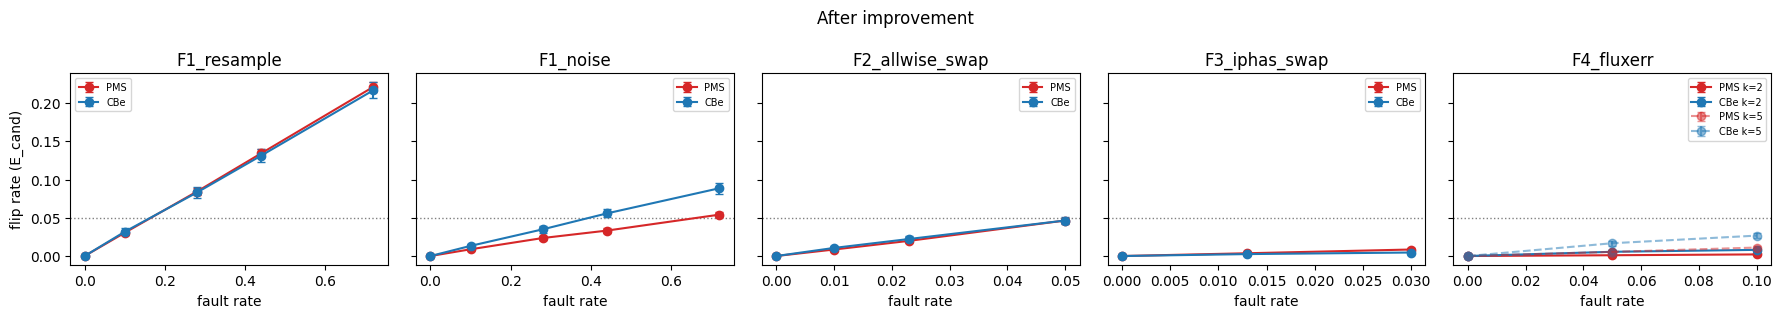

In [10]:
if after is None:
    print('results/after not present yet')
else:
    ta = A.cell_table(after)
    keep = ['flip_PMS_cand', 'flip_CBe_cand', 'd_recall_PMS', 'recall_PMS', 'precision_PMS', 'dN_PMS_rand', 'dN_CBe_rand']
    ba = tb[['cell'] + keep].merge(ta[['cell'] + keep], on='cell', suffixes=('_before', '_after'))
    display(ba.round(4))
    da = A.decisions(after, ta); display(da)
    print('C1 after improvement:', 'FALSIFIED' if da.falsifies_C1.any() else 'SURVIVED')
    t2a = c2_table(after)
    display(t2b[['case', 'verdict']].merge(t2a[['case', 'verdict', 'outcome']], on='case', suffixes=('_before', '_after')))
    print('C2 after improvement:', 'FALSIFIED' if (t2a.verdict == 'FAIL-silent').any() else 'SURVIVED')
    curves(ta, 'After improvement')

### 8b. Decomposing flips: guard rejections vs real class changes
Under the frozen oracle, a source the guard rejects (class 'undefined') counts as a flip. The table
separates rejections from changes to another class.

In [11]:
if after is not None:
    rc_cells = [n for n, c in zip(names, base['cfg']['cells']) if any(c['fault'] == r['fault'] and np.isclose(c['rate'], r['rate']) for r in base['cfg']['realistic'])]
    for lab, run in [('baseline', base), ('after', after)]:
        fd = A.flip_decomposition(run); print(lab); display(fd[fd.cell.isin(rc_cells)].round(4))
    sup = json.loads((ROOT / 'results/after/supplementary_bootgather_unflagged.json').read_text())
    print('SUPPLEMENTARY (not a protocol cell): original Bootgather.py on the', sup['n_sources_in'],
          'unflagged rows after the improvement ->', sup['n_ids_altered'], 'IDs silently altered. The protocol-cell PASS after the improvement',
          'is a crash caused by the guard NaN output (returncode', after['c2']['bootgather']['returncode'], ').')

baseline


,cell,PMS_n,PMS_rejected,PMS_changed_class,CBe_n,CBe_rejected,CBe_changed_class
3,c03_F1_resample_0.44,16952,0.0,0.1050,6503,0.0,0.0953
7,c07_F1_noise_0.44,16952,0.0,0.0302,6503,0.0,0.0466
10,c10_F2_allwise_swap_0.023,16952,0.0,0.0190,6503,0.0,0.0188
12,c12_F3_iphas_swap_0.013,16952,0.0,0.0035,6503,0.0,0.0025


after


,cell,PMS_n,PMS_rejected,PMS_changed_class,CBe_n,CBe_rejected,CBe_changed_class
3,c03_F1_resample_0.44,16570,0.0594,0.0748,6332,0.0433,0.0880
7,c07_F1_noise_0.44,16570,0.0035,0.0298,6332,0.0085,0.0472
10,c10_F2_allwise_swap_0.023,16570,0.0027,0.0171,6332,0.0079,0.0144
12,c12_F3_iphas_swap_0.013,16570,0.0000,0.0036,6332,0.0000,0.0025


SUPPLEMENTARY (not a protocol cell): original Bootgather.py on the 999 unflagged rows after the improvement -> 790 IDs silently altered. The protocol-cell PASS after the improvement is a crash caused by the guard NaN output (returncode 1 ).


## 9. Side effects of the improvement

In [12]:
if after is not None:
    se = {}
    tb0, ta0 = tb.iloc[0], ta.iloc[0]
    se['clean recall_PMS before/after'] = (tb0.recall_PMS, ta0.recall_PMS)
    se['clean precision_PMS before/after (lower limits)'] = (tb0.precision_PMS, ta0.precision_PMS)
    se['clean N_PMS candidates on E_rand before/after'] = (tb0.N_PMS_rand, ta0.N_PMS_rand)
    se['training+grid wall time [s] before/after'] = (base['meta']['wall_seconds'], after['meta']['wall_seconds'])
    se['training seconds per seed before'] = [t['train_seconds'] for t in base['training']]
    se['training seconds per seed after'] = [t['train_seconds'] for t in after['training']]
    p = ROOT / 'results/after/side_effects.json'
    if p.exists():
        se.update(json.loads(p.read_text()))
    for k, v in se.items(): print(f'{k}: {v}')

clean recall_PMS before/after: (0.7492063492063492, 0.7492063492063492)
clean precision_PMS before/after (lower limits): (0.3786087878159489, 0.3808632161573338)
clean N_PMS candidates on E_rand before/after: (528.6666666666666, 518.0)
training+grid wall time [s] before/after: (646.5, 555.2)
training seconds per seed before: [167.3, 131.7, 250.6]
training seconds per seed after: [180.2, 109.7, 185.6]
false_rejections_clean: {'seed11_test': {'n': 2, 'of': 4722, 'rate': 0.00042354934349851756}, 'seed11_cand': {'n': 171, 'of': 10399, 'rate': 0.016443888835464947}, 'seed11_rand': {'n': 72, 'of': 100000, 'rate': 0.00072}, 'seed11_test_by_label': {'0': 2, '1': 0, '2': 0}, 'seed22_test': {'n': 2, 'of': 4722, 'rate': 0.00042354934349851756}, 'seed22_cand': {'n': 189, 'of': 10399, 'rate': 0.018174824502355996}, 'seed22_rand': {'n': 79, 'of': 100000, 'rate': 0.00079}, 'seed22_test_by_label': {'0': 2, '1': 0, '2': 0}, 'seed33_test': {'n': 4, 'of': 4722, 'rate': 0.0008470986869970351}, 'seed33_can

## 10. Verdict, negative results and limits

The verdict cells below print the decision rules evaluated above. The limits apply to every number in
this notebook:

- **Reproduction, not the original model.** No weights or labels were published. Labels are SIMBAD
  `Ae*`/`TT*`/`Be*` stars present in the published table, largely disjoint from the authors' set.
- **Reduced bootstrap.** 3 models instead of the paper's 30. The "other" class is 1/10 of the paper's
  size and training is capped at 300 epochs, so the absolute recall and precision are not comparable
  with 78.8 % / 40.7 %.
- **Synthetic faults.** These are not real mismatched photometry. The F1 noise σ = 1 mag is an
  assumption, and F4 has no literature rate.
- **Gaia DR2-era data.** Inputs from 2018–2020, and SIMBAD as queried on 2026-11-07.
- **Precision is only a lower limit** (paper Appx. B.1).

In [13]:
print('C1 baseline:', 'FALSIFIED' if C1_falsified else 'SURVIVED')
print(db[['cell', 'falsifies_C1', 'rule_a_PMS', 'rule_a_CBe', 'rule_b_recall']].to_string(index=False))
print('C2 baseline:', 'FALSIFIED' if C2_falsified else 'SURVIVED')
print('C2 FAIL-silent cases:', ', '.join(t2b[t2b.verdict == 'FAIL-silent'].case))
print('C2 FAIL-crash (valid input) cases:', ', '.join(t2b[t2b.verdict == 'FAIL-crash'].case))
fails = list(Path(ROOT / 'results/baseline/failures').glob('*'))
print('crashed grid cells kept in results/baseline/failures:', len(fails))

C1 baseline: FALSIFIED
                     cell  falsifies_C1  rule_a_PMS  rule_a_CBe  rule_b_recall
     c03_F1_resample_0.44          True        True        True           True
        c07_F1_noise_0.44         False       False       False          False
c10_F2_allwise_swap_0.023         False       False       False          False
  c12_F3_iphas_swap_0.013         False       False       False          False
C2 baseline: FALSIFIED
C2 FAIL-silent cases: W3_mag_99, G_mag_minus50, rHa_colour_50, Gvar_negative, column_order_J_W4_swapped, duplicate_source_id, gaia_id_roundtrip, bootgather_original_ids
C2 FAIL-crash (valid input) cases: single_row
crashed grid cells kept in results/baseline/failures: 0
